In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip -q install torch-fidelity scikit-image tqdm

In [3]:
import json, random
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42

DATASET = "FashionMNIST"
BATCH_SIZE = 128
NUM_WORKERS = 2

TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.80, 0.10, 0.10

DATA_ROOT = Path("/content/data")
DRIVE_ROOT = Path("/content/drive/MyDrive/DL_Sesi07")
CKPT_DIR = DRIVE_ROOT / "checkpoints"
FIG_DIR = DRIVE_ROOT / "figures"
RESULT_DIR = DRIVE_ROOT / "results"
SPLIT_FILE = RESULT_DIR / f"split_indices_{DATASET}_seed{SEED}.json"

In [4]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def ensure_dirs(*dirs):
    for d in dirs:
        Path(d).mkdir(parents=True, exist_ok=True)


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def save_checkpoint(path, model, optimizer, epoch, history=None, extra=None):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict() if optimizer is not None else None,
        "epoch": epoch,
        "history": history or {},
        "extra": extra or {},
    }, path)


def load_checkpoint(path, model, optimizer=None, map_location=None):
    ckpt = torch.load(path, map_location=map_location)
    model.load_state_dict(ckpt["model"])
    if optimizer is not None and ckpt.get("optimizer") is not None:
        optimizer.load_state_dict(ckpt["optimizer"])
    return ckpt["epoch"], ckpt.get("history", {}), ckpt.get("extra", {})

In [5]:
_DATASETS = {
    "FashionMNIST": datasets.FashionMNIST,
    "MNIST": datasets.MNIST,
    "KMNIST": datasets.KMNIST,
    "CIFAR10": datasets.CIFAR10,
}


def get_full_dataset(name=DATASET, root=DATA_ROOT):
    cls = _DATASETS[name]
    tf = transforms.ToTensor()
    train = cls(root=str(root), train=True, download=True, transform=tf)
    test = cls(root=str(root), train=False, download=True, transform=tf)
    return ConcatDataset([train, test])


def make_split_indices(n, seed=SEED, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(n)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    return {
        "train": perm[:n_train].tolist(),
        "val": perm[n_train:n_train + n_val].tolist(),
        "test": perm[n_train + n_val:].tolist(),
    }


def get_split_indices(n, split_file=SPLIT_FILE):
    try:
        idx = load_json(split_file)
        print(f"[split] dimuat dari {split_file}")
    except FileNotFoundError:
        idx = make_split_indices(n)
        save_json(idx, split_file)
        print(f"[split] dibuat baru dan disimpan ke {split_file}")
    return idx


def get_datasets(name=DATASET):
    full = get_full_dataset(name)
    idx = get_split_indices(len(full))
    return {k: Subset(full, v) for k, v in idx.items()}


def get_loaders(batch_size=BATCH_SIZE, name=DATASET):
    ds = get_datasets(name)
    g = torch.Generator()
    g.manual_seed(SEED)
    return {
        "train": DataLoader(ds["train"], batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS, generator=g),
        "val": DataLoader(ds["val"], batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS),
        "test": DataLoader(ds["test"], batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS),
    }


def to_minus1_1(x):
    return x * 2.0 - 1.0


def from_minus1_1(x):
    return ((x + 1.0) / 2.0).clamp(0.0, 1.0)

In [6]:
set_seed(SEED)
device = get_device()
ensure_dirs(CKPT_DIR, FIG_DIR, RESULT_DIR)
print("Device:", device)
print("Dataset:", DATASET, "| Seed:", SEED, "| Batch:", BATCH_SIZE)

Device: cuda
Dataset: FashionMNIST | Seed: 42 | Batch: 128


In [7]:
ds = get_datasets()
print({k: len(v) for k, v in ds.items()})

loaders = get_loaders()
x, y = next(iter(loaders['train']))
print("Batch:", x.shape, y.shape, "| min/max:", x.min().item(), x.max().item())

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 173kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 8.90MB/s]


[split] dibuat baru dan disimpan ke /content/drive/MyDrive/DL_Sesi07/results/split_indices_FashionMNIST_seed42.json
{'train': 56000, 'val': 7000, 'test': 7000}
[split] dimuat dari /content/drive/MyDrive/DL_Sesi07/results/split_indices_FashionMNIST_seed42.json
Batch: torch.Size([128, 1, 28, 28]) torch.Size([128]) | min/max: 0.0 1.0


In [9]:
idx = load_json(SPLIT_FILE)
s_tr, s_va, s_te = set(idx['train']), set(idx['val']), set(idx['test'])
print(f"train={len(s_tr)} val={len(s_va)} test={len(s_te)} total={len(s_tr)+len(s_va)+len(s_te)}")

train=56000 val=7000 test=7000 total=70000


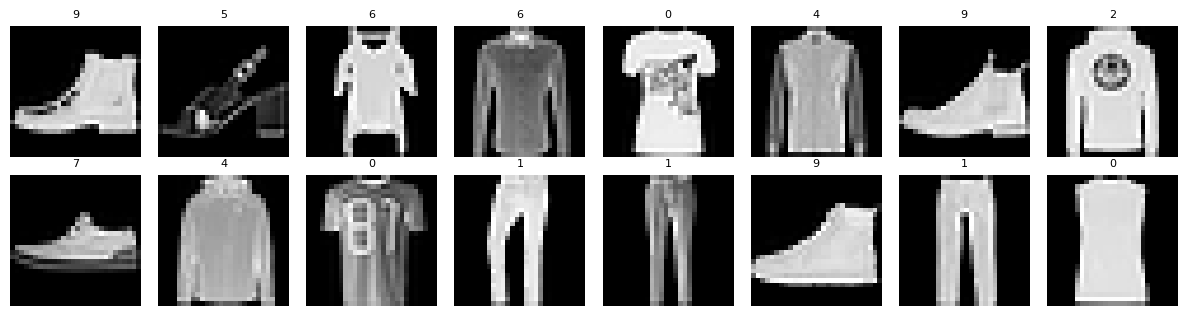

In [11]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i, ax in enumerate(axes.flat):
    img = x[i].squeeze().cpu().numpy() if x[i].shape[0] == 1 else x[i].permute(1, 2, 0).cpu().numpy()
    ax.imshow(img, cmap='gray' if x[i].shape[0] == 1 else None)
    ax.set_title(int(y[i]), fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [12]:
import time
import torch.nn as nn
import torch.nn.functional as F
from skimage.metrics import structural_similarity as sk_ssim

_x0, _ = next(iter(loaders['train']))
IMG_SHAPE = tuple(_x0.shape[1:])
IN_DIM = int(np.prod(IMG_SHAPE))

def flat(x):
    return x.reshape(x.size(0), -1)

@torch.no_grad()
def evaluate_recon(recon_fn, loader):
    mses, psnrs, ssims = [], [], []
    for x, _ in loader:
        x = x.to(device)
        xh = recon_fn(x).clamp(0, 1)
        mse = ((xh - flat(x)) ** 2).mean(1)
        mses.append(mse.cpu())
        psnrs.append((10 * torch.log10(1.0 / mse.clamp_min(1e-10))).cpu())
        a = x.cpu().numpy()
        b = xh.reshape(x.shape).cpu().numpy()
        for i in range(a.shape[0]):
            if IMG_SHAPE[0] == 1:
                ssims.append(sk_ssim(a[i, 0], b[i, 0], data_range=1.0))
            else:
                ssims.append(sk_ssim(a[i], b[i], data_range=1.0, channel_axis=0))
    return {"mse": torch.cat(mses).mean().item(),
            "psnr": torch.cat(psnrs).mean().item(),
            "ssim": float(np.mean(ssims))}

In [13]:
class MLPClassifier(nn.Module):
    def __init__(self, in_dim=IN_DIM, h1=256, z_dim=64, n_cls=10):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, h1)
        self.fc2 = nn.Linear(h1, z_dim)
        self.fc3 = nn.Linear(z_dim, n_cls)

    def features(self, x):
        h1 = F.relu(self.fc1(flat(x)))
        return F.relu(self.fc2(h1))

    def forward(self, x):
        return self.fc3(self.features(x))


@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = n = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        n += y.size(0)
    return correct / n


set_seed(SEED)
mlp = MLPClassifier().to(device)
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
EPOCHS_MLP = 30
hist_mlp = {"train_loss": [], "val_acc": []}
best_val, best_state = 0.0, None

for ep in range(1, EPOCHS_MLP + 1):
    mlp.train()
    tot = n = 0
    for x, y in loaders['train']:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(mlp(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * y.size(0); n += y.size(0)
    va = accuracy(mlp, loaders['val'])
    hist_mlp["train_loss"].append(tot / n); hist_mlp["val_acc"].append(va)
    if va > best_val:
        best_val = va
        best_state = {k: v.clone() for k, v in mlp.state_dict().items()}
    print(f"Epoch {ep:02d} | loss {tot/n:.4f} | val acc {va:.4f}")

mlp.load_state_dict(best_state)
test_acc = accuracy(mlp, loaders['test'])
print(f"\nTEST ACCURACY: {test_acc:.4f}")
save_checkpoint(CKPT_DIR / "mlp_classifier.pt", mlp, opt, EPOCHS_MLP, hist_mlp)
save_json(hist_mlp, RESULT_DIR / "mlp_classifier_history.json")

Epoch 01 | loss 0.6045 | val acc 0.8370
Epoch 02 | loss 0.4169 | val acc 0.8609
Epoch 03 | loss 0.3669 | val acc 0.8646
Epoch 04 | loss 0.3366 | val acc 0.8750
Epoch 05 | loss 0.3166 | val acc 0.8749
Epoch 06 | loss 0.2973 | val acc 0.8796
Epoch 07 | loss 0.2856 | val acc 0.8804
Epoch 08 | loss 0.2751 | val acc 0.8791
Epoch 09 | loss 0.2614 | val acc 0.8847
Epoch 10 | loss 0.2538 | val acc 0.8916
Epoch 11 | loss 0.2436 | val acc 0.8924
Epoch 12 | loss 0.2361 | val acc 0.8946
Epoch 13 | loss 0.2271 | val acc 0.8851
Epoch 14 | loss 0.2209 | val acc 0.8947
Epoch 15 | loss 0.2111 | val acc 0.8953
Epoch 16 | loss 0.2057 | val acc 0.8961
Epoch 17 | loss 0.2010 | val acc 0.8991
Epoch 18 | loss 0.1932 | val acc 0.8984
Epoch 19 | loss 0.1866 | val acc 0.8949
Epoch 20 | loss 0.1823 | val acc 0.8966
Epoch 21 | loss 0.1753 | val acc 0.8980
Epoch 22 | loss 0.1718 | val acc 0.9006
Epoch 23 | loss 0.1679 | val acc 0.8986
Epoch 24 | loss 0.1615 | val acc 0.9001
Epoch 25 | loss 0.1542 | val acc 0.8991


In [14]:
for p in mlp.parameters():
    p.requires_grad = False
mlp.eval()

W1, W2, W3 = mlp.fc1.weight.detach(), mlp.fc2.weight.detach(), mlp.fc3.weight.detach()

def orth_error(W):
    G = W @ W.T
    I = torch.eye(G.size(0), device=W.device)
    return ((G - I).norm() / I.norm()).item()

for name, W in [("W1", W1), ("W2", W2), ("W3", W3)]:
    S = torch.linalg.svdvals(W)
    print(f"{name} {tuple(W.shape)} | ||WW^T - I||_F/||I||_F = {orth_error(W):.3f} | rank maks = {min(W.shape)} (dimensi input {W.shape[1]}) | cond = {(S.max()/S.min()).item():.1f}")

with torch.no_grad():
    xb, _ = next(iter(loaders['test']))
    xb = xb.to(device)
    a1 = mlp.fc1(flat(xb)); a2 = mlp.fc2(F.relu(a1))
    print(f"\nFraksi unit dipotong ReLU: layer1 = {(a1 <= 0).float().mean():.3f} layer2 (z_MLP) = {(a2 <= 0).float().mean():.3f}")

W1 (256, 784) | ||WW^T - I||_F/||I||_F = 34.888 | rank maks = 256 (dimensi input 784) | cond = 42.1
W2 (64, 256) | ||WW^T - I||_F/||I||_F = 10.624 | rank maks = 64 (dimensi input 256) | cond = 17.9
W3 (10, 64) | ||WW^T - I||_F/||I||_F = 4.735 | rank maks = 10 (dimensi input 64) | cond = 2.7

Fraksi unit dipotong ReLU: layer1 = 0.748 layer2 (z_MLP) = 0.511


In [15]:
@torch.no_grad()
def backproject_from_class():
    n_cls = W3.size(0)
    Y = torch.eye(n_cls, device=device)
    z_hat = F.relu(Y @ W3)
    h1_hat = F.relu(z_hat @ W2)
    return torch.sigmoid(h1_hat @ W1)

xhat_cls = backproject_from_class()

class_means = torch.zeros(W3.size(0), IN_DIM, device=device)
counts = torch.zeros(W3.size(0), device=device)
for x, y in loaders['test']:
    x, y = x.to(device), y.to(device)
    for c in range(W3.size(0)):
        m = (y == c)
        class_means[c] += flat(x)[m].sum(0); counts[c] += m.sum()
class_means /= counts.unsqueeze(1)

print("MSE(x_hat vs rata-rata kelas):", F.mse_loss(xhat_cls, class_means).item())
print("Std piksel x_hat (rendah = bercak datar):", xhat_cls.std(1).mean().item())
print("Std piksel rata-rata kelas asli       :", class_means.std(1).mean().item())

MSE(x_hat vs rata-rata kelas): 0.11378875374794006
Std piksel x_hat (rendah = bercak datar): 0.1498904526233673
Std piksel rata-rata kelas asli       : 0.25228187441825867


In [16]:
@torch.no_grad()
def backproject_from_latent(z):
    return torch.sigmoid(F.relu(z @ W2) @ W1)

res_stage3 = evaluate_recon(lambda x: backproject_from_latent(mlp.features(x)), loaders['test'])
print("Tahap 3 (W^T dari z_MLP) pada test set:", res_stage3)

Tahap 3 (W^T dari z_MLP) pada test set: {'mse': 0.30585289001464844, 'psnr': 5.198549747467041, 'ssim': 0.05505660687923361}


In [17]:
class MLPDecoder(nn.Module):
    def __init__(self, z_dim=64, h=256, out_dim=IN_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, out_dim), nn.Sigmoid())
    def forward(self, z):
        return self.net(z)


class FrozenLatentRecon(nn.Module):
    def __init__(self, mlp, z_dim=64):
        super().__init__()
        self.mlp = mlp
        self.dec = MLPDecoder(z_dim)
    def train(self, mode=True):
        super().train(mode)
        self.mlp.eval()
        return self
    def forward(self, x):
        with torch.no_grad():
            z = self.mlp.features(x)
        return self.dec(z)


class VanillaAE(nn.Module):
    def __init__(self, in_dim=IN_DIM, h=256, z_dim=64):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(in_dim, h), nn.ReLU(), nn.Linear(h, z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, in_dim), nn.Sigmoid())
    def encode(self, x):
        return self.enc(flat(x))
    def forward(self, x):
        return self.dec(self.encode(x))


def fit_recon(model, epochs=30, lr=1e-3, ckpt_name=None):
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr)
    hist = {"train_loss": [], "val_loss": [], "epoch_time": []}
    best_val, best_state = float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train(); tot = n = 0
        for x, _ in loaders['train']:
            x = x.to(device)
            loss = F.mse_loss(model(x), flat(x))
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * x.size(0); n += x.size(0)
        model.eval(); vt = vn = 0
        with torch.no_grad():
            for x, _ in loaders['val']:
                x = x.to(device)
                vt += F.mse_loss(model(x), flat(x), reduction='sum').item() / IN_DIM
                vn += x.size(0)
        if device.type == "cuda":
            torch.cuda.synchronize()
        hist["train_loss"].append(tot / n); hist["val_loss"].append(vt / vn)
        hist["epoch_time"].append(time.time() - t0)
        if vt / vn < best_val:
            best_val = vt / vn
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        print(f"Epoch {ep:02d} | train {tot/n:.5f} | val {vt/vn:.5f} | {hist['epoch_time'][-1]:.1f}s")
    model.load_state_dict(best_state)
    if ckpt_name:
        save_checkpoint(CKPT_DIR / f"{ckpt_name}.pt", model, opt, epochs, hist)
        save_json(hist, RESULT_DIR / f"{ckpt_name}_history.json")
    return hist


EPOCHS_REC = 30

print("Frozen latent decoder")
set_seed(SEED)
frozen_model = FrozenLatentRecon(mlp)
hist_frozen = fit_recon(frozen_model, EPOCHS_REC, ckpt_name="frozen_latent_decoder")

print("\nVanilla AE (latent 64)")
set_seed(SEED)
vae64 = VanillaAE()
hist_vae64 = fit_recon(vae64, EPOCHS_REC, ckpt_name="vanilla_ae_z64")

frozen_model.eval(); vae64.eval()
res_frozen = evaluate_recon(lambda x: frozen_model(x), loaders['test'])
res_ae = evaluate_recon(lambda x: vae64(x), loaders['test'])

print("\nTest set: z_MLP vs z_AE, latent 64")
print(f"{'Model':<28}{'MSE':>10}{'PSNR (dB)':>12}{'SSIM':>9}")
for name, r in [("Frozen z_MLP + Decoder", res_frozen), ("Vanilla AE (z_AE)", res_ae)]:
    print(f"{name:<28}{r['mse']:>10.5f}{r['psnr']:>12.2f}{r['ssim']:>9.4f}")

Frozen latent decoder
Epoch 01 | train 0.03634 | val 0.02746 | 7.3s
Epoch 02 | train 0.02493 | val 0.02407 | 8.9s
Epoch 03 | train 0.02273 | val 0.02270 | 7.2s
Epoch 04 | train 0.02152 | val 0.02145 | 8.7s
Epoch 05 | train 0.02072 | val 0.02074 | 14.2s
Epoch 06 | train 0.02015 | val 0.02068 | 11.2s
Epoch 07 | train 0.01974 | val 0.02007 | 8.7s
Epoch 08 | train 0.01935 | val 0.01993 | 8.4s
Epoch 09 | train 0.01909 | val 0.01950 | 7.3s
Epoch 10 | train 0.01883 | val 0.01923 | 8.4s
Epoch 11 | train 0.01864 | val 0.01910 | 7.4s
Epoch 12 | train 0.01848 | val 0.01887 | 8.4s
Epoch 13 | train 0.01828 | val 0.01878 | 8.3s
Epoch 14 | train 0.01817 | val 0.01871 | 7.7s
Epoch 15 | train 0.01806 | val 0.01859 | 8.5s
Epoch 16 | train 0.01797 | val 0.01856 | 7.4s
Epoch 17 | train 0.01785 | val 0.01847 | 8.5s
Epoch 18 | train 0.01776 | val 0.01843 | 7.0s
Epoch 19 | train 0.01767 | val 0.01828 | 8.5s
Epoch 20 | train 0.01763 | val 0.01824 | 7.0s
Epoch 21 | train 0.01755 | val 0.01808 | 9.2s
Epoch 22 |

In [18]:
@torch.no_grad()
def collect_latents(loader):
    return torch.cat([mlp.features(x.to(device)) for x, _ in loader])

Z_test = collect_latents(loaders['test'])
mu_z, sigma_z = Z_test.mean(0), Z_test.std(0)

set_seed(SEED)
z_rand = mu_z + sigma_z * torch.randn(16, Z_test.size(1), device=device)
with torch.no_grad():
    x_rand = frozen_model.dec(z_rand)

print(f"Fraksi komponen z_rand bernilai negatif: {(z_rand < 0).float().mean():.3f} (z_MLP asli hasil ReLU selalu >= 0)")
print(f"Fraksi komponen z_MLP asli yang bernilai 0 : {(Z_test == 0).float().mean():.3f}")

Fraksi komponen z_rand bernilai negatif: 0.206 (z_MLP asli hasil ReLU selalu >= 0)
Fraksi komponen z_MLP asli yang bernilai 0 : 0.515


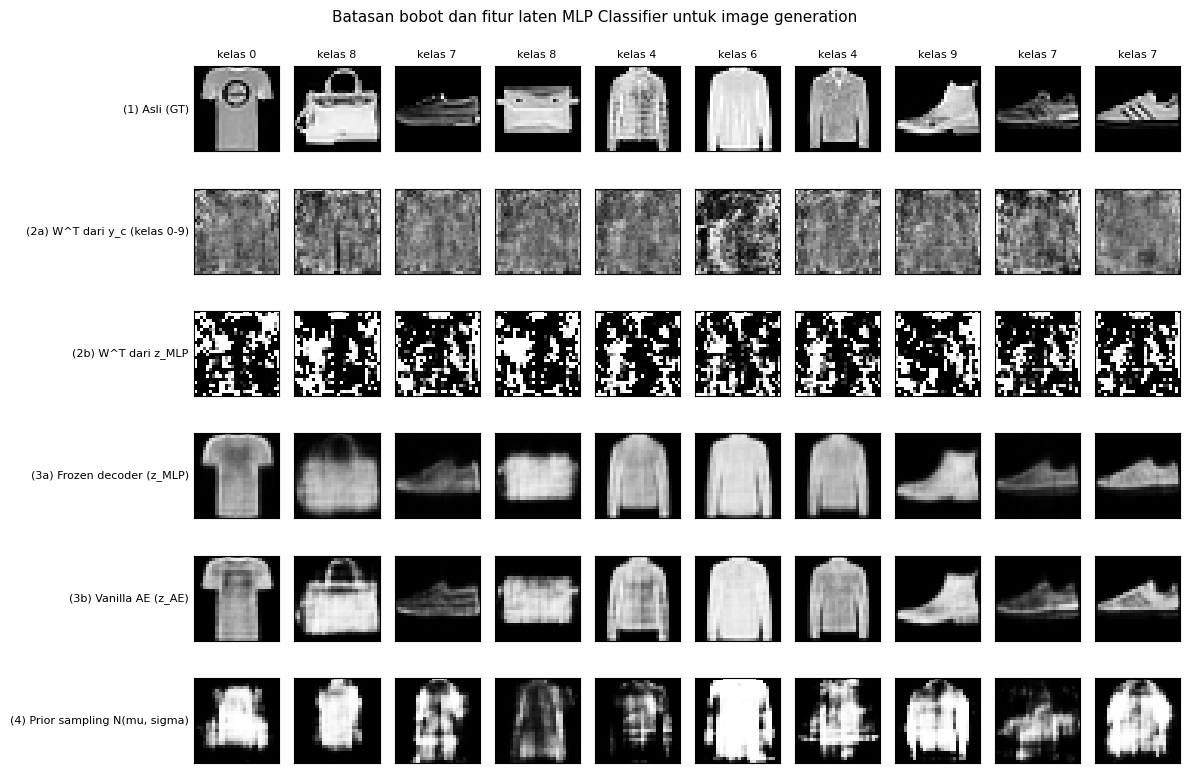

In [19]:
def to_img(t):
    return t.reshape(-1, *IMG_SHAPE).cpu()

def show_row(axes, imgs, ylabel):
    for j, ax in enumerate(axes):
        im = imgs[j]
        im = im[0] if IMG_SHAPE[0] == 1 else im.permute(1, 2, 0)
        ax.imshow(im.numpy(), cmap='gray' if IMG_SHAPE[0] == 1 else None, vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    axes[0].set_ylabel(ylabel, rotation=0, ha='right', va='center', fontsize=8)

x10, y10 = next(iter(loaders['test']))
x10, y10 = x10[:10].to(device), y10[:10]

with torch.no_grad():
    z10 = mlp.features(x10)
    rows = [
        ("(1) Asli (GT)", x10),
        ("(2a) W^T dari y_c (kelas 0-9)", xhat_cls[:10]),
        ("(2b) W^T dari z_MLP", backproject_from_latent(z10)),
        ("(3a) Frozen decoder (z_MLP)", frozen_model(x10)),
        ("(3b) Vanilla AE (z_AE)", vae64(x10)),
        ("(4) Prior sampling N(mu, sigma)", x_rand[:10]),
    ]

fig, axes = plt.subplots(len(rows), 10, figsize=(12, 8))
for r, (label, imgs) in enumerate(rows):
    show_row(axes[r], to_img(imgs), label)
for j in range(10):
    axes[0][j].set_title(f"kelas {int(y10[j])}", fontsize=8)
fig.suptitle("Batasan bobot dan fitur laten MLP Classifier untuk image generation", fontsize=11)
plt.tight_layout()
fig.savefig(FIG_DIR / "fig3_mlp_classifier_limits.png", dpi=200, bbox_inches='tight')
plt.show()

In [20]:
save_json({
    "mlp_test_acc": test_acc,
    "stage3_W_transpose_from_z": res_stage3,
    "stage4_frozen_latent_decoder": res_frozen,
    "stage4_vanilla_ae_z64": res_ae,
    "orth_error": {n: orth_error(W) for n, W in [("W1", W1), ("W2", W2), ("W3", W3)]},
}, RESULT_DIR / "mlp_proof_metrics.json")
print("Tersimpan di:", RESULT_DIR / "mlp_proof_metrics.json")

Tersimpan di: /content/drive/MyDrive/DL_Sesi07/results/mlp_proof_metrics.json
